# B-6511502A · validação do modelo novo para o deploy

**O modelo novo** usa 11 sensores: as 8 vibrações radiais, a corrente do motor e as pressões de sucção e descarga.
Saíram a temperatura do mancal LNA do motor (TE-07A) e o deslocamento axial (ZE-50/51): não carregam a falha de 2023 e
geram alarme quando mudam por outro motivo (`sensores_b6511502a.ipynb`). Mesma janela de treino do modelo atual
(20/05/2022 a 17/04/2023), mesma regra de alarme (limiar μ+5σ, 15 de 20 leituras, alerta ≥ 1 h).

**A validação é um catálogo de comportamentos:** em cada situação, o que esperamos do modelo e o que ele faz, lado a
lado com o modelo atual (14 sensores). Assim fica documentado, antes do deploy, quando ele alerta e quando não.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "scripts")); sys.path.insert(0, str(RAIZ / "src"))
import b6511502a_v2 as v2
ds = v2.ds
R = RAIZ / "results/b6511502a_v2"
cat = pd.read_csv(R / "catalogo.csv"); cands = pd.read_csv(R / "candidatos.csv")
NOVO = next(R.glob("model_*_VAE_11s")); ATUAL = ds.PRODUCAO
MODELOS = {"atual (14 sensores)": (ATUAL, "#8a897f"), "novo (11 sensores)": (NOVO, "#1baf7a")}
raw = ds.load_equipment_data(ds.EQ)
VERMELHO, SERIE, TEXTO = "#e5484d", "#6f9fd1", "#52514e"
plt.rcParams.update({"font.size": 11})
def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)
print("modelo novo:", NOVO.name, "· candidato", json.loads((NOVO / "alarm.json").read_text())["threshold_calibration"]["candidate"])

modelo novo: model_2022-05-20_2023-04-18_VAE_11s · candidato l128-64-32_lat16_lr0.0001_s2


## 1. O catálogo de comportamentos

Cada linha é uma situação; à direita, o que cada modelo faz. **Verde** = fez o esperado (para "alerta": alertou na primeira semana); **laranja** = não fez;
**cinza** = situação de sensibilidade (não há resposta certa: mostra até onde ele enxerga). As mudanças começam em
01/02/2023 e valem até uma semana antes da falha; sensor zerado e travado são de 1 e 2 dias em 01/03/2023.

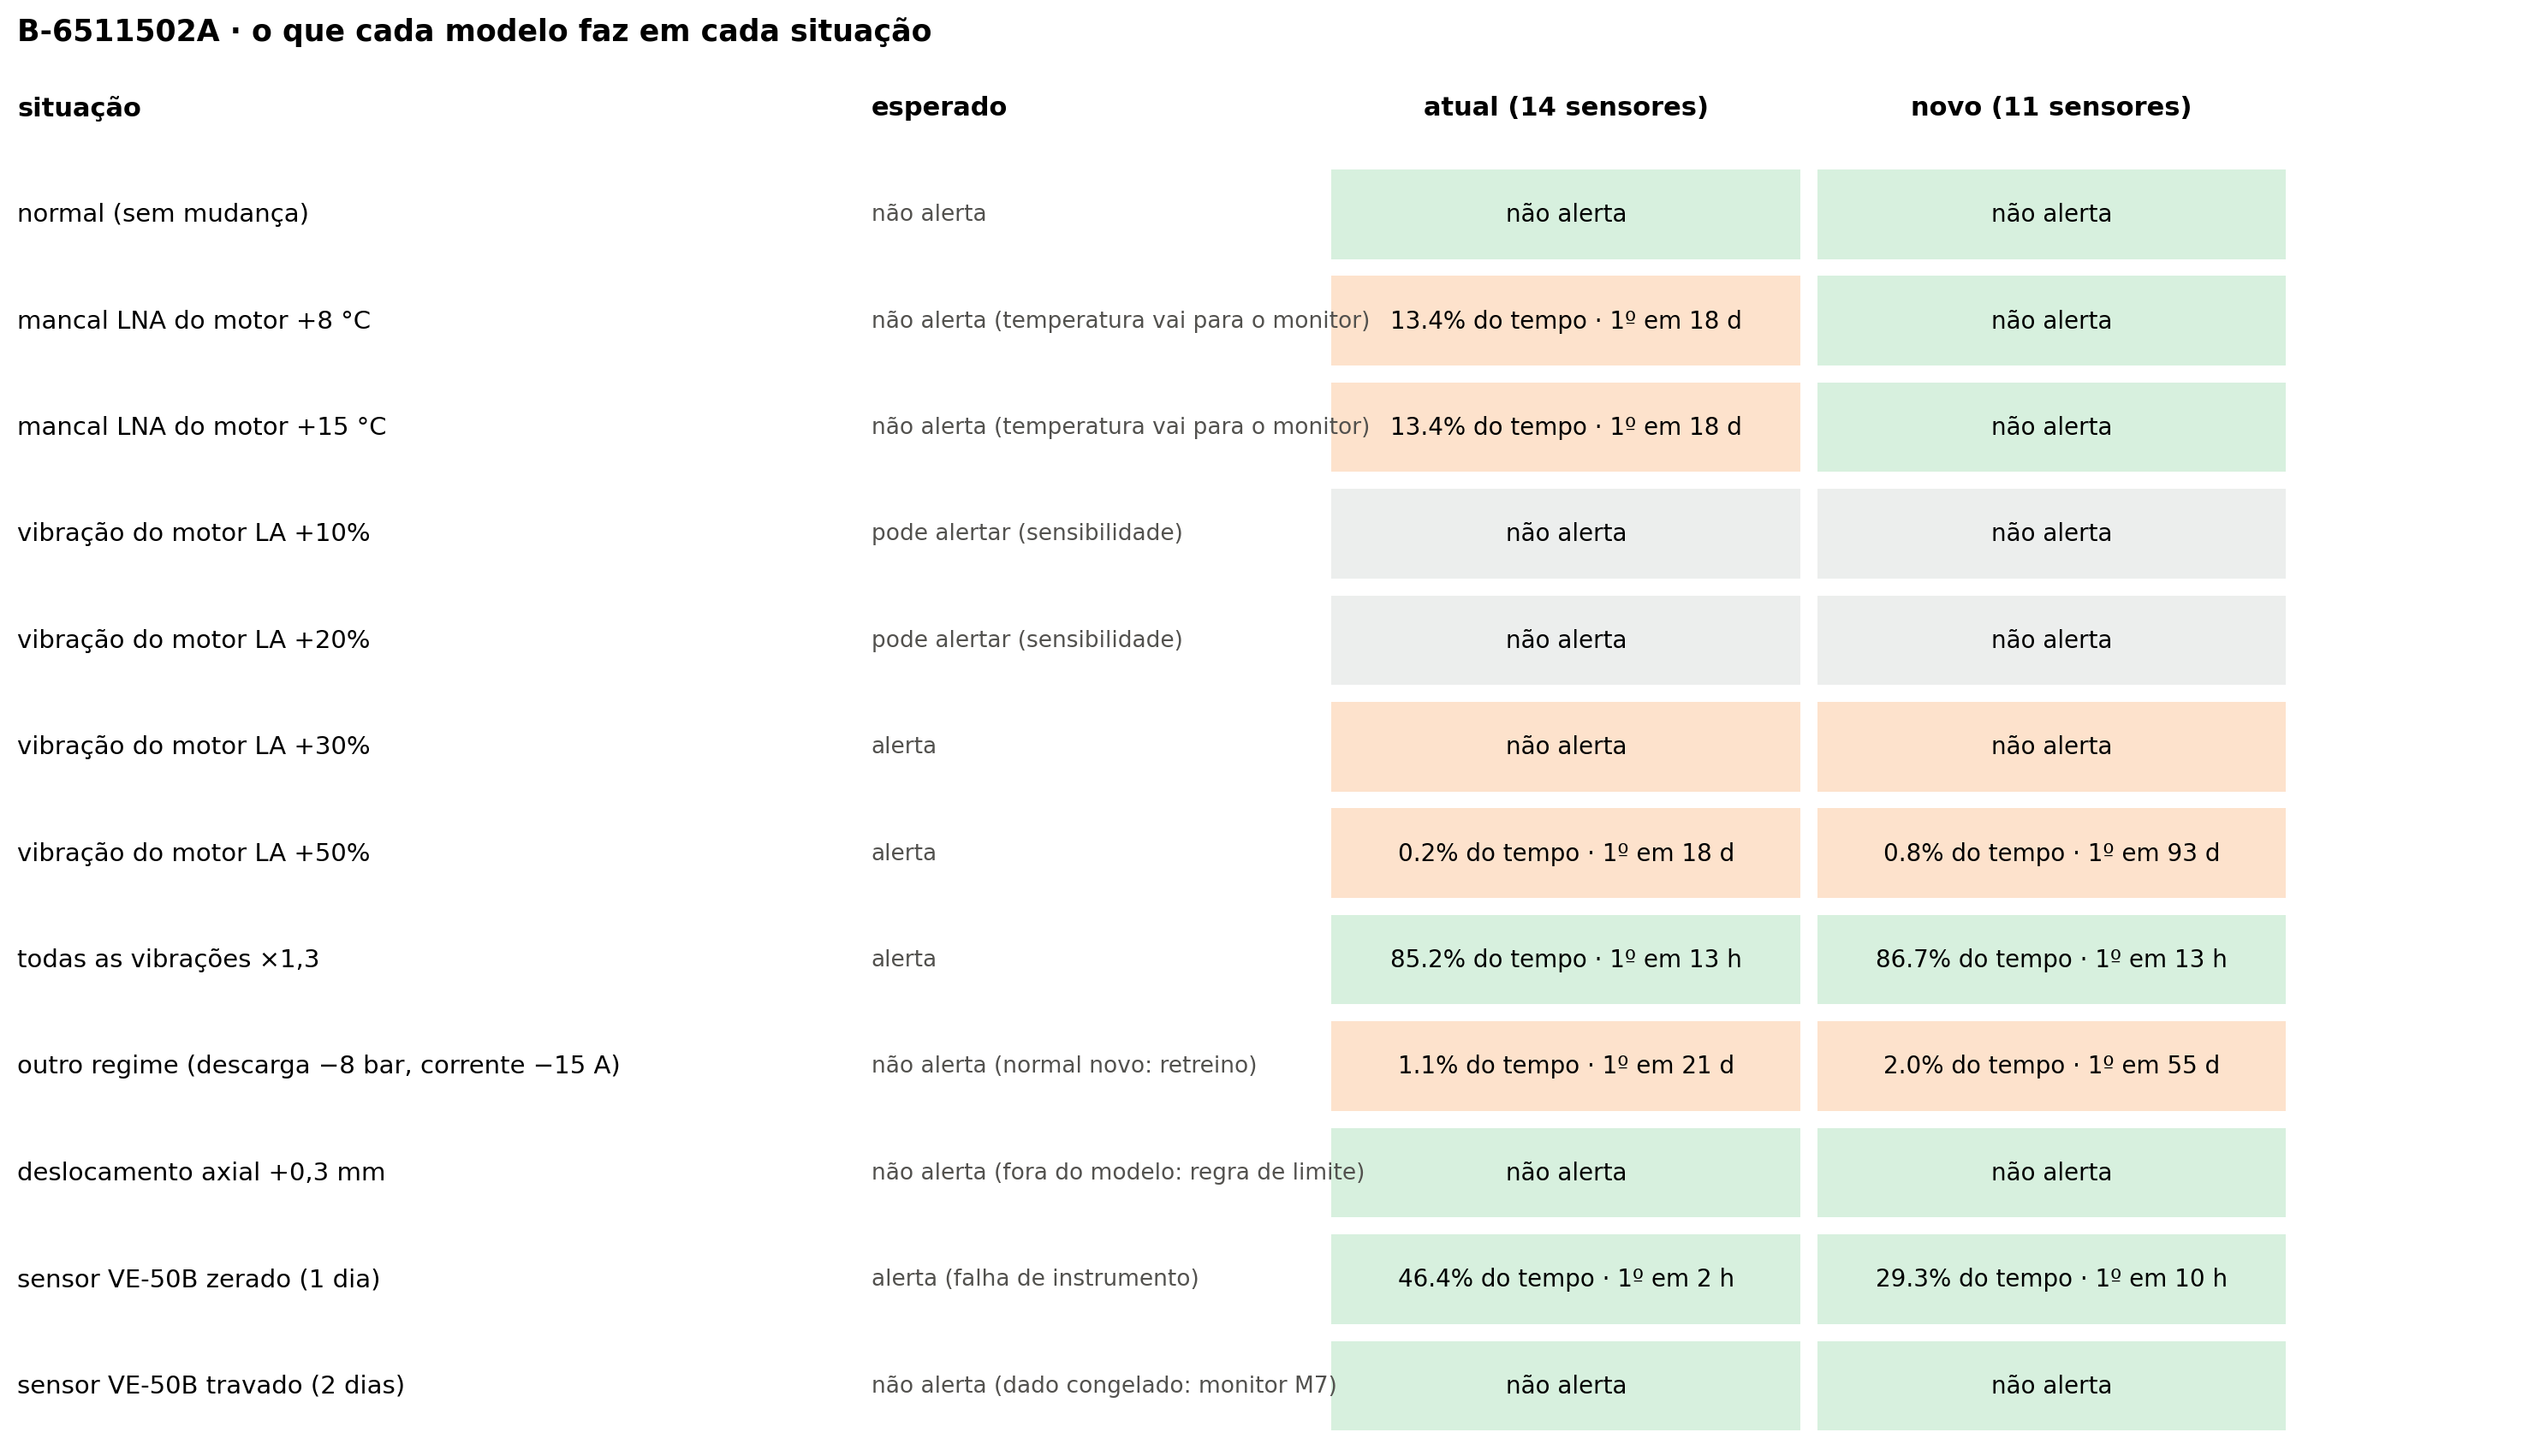

In [2]:
sit = cat[~cat["situação"].str.startswith("falha")].copy()
def avalia(r):
    p, e = r["% do tempo em alerta"], r["esperado"]
    if e.startswith("pode"): return "cinza"
    h = r["1º alerta (h depois)"]
    if e.startswith("alerta"):                                # alerta que serve: dentro de 1 semana da mudança
        return "verde" if (p >= 0.5 and pd.notna(h) and h <= 168) else "laranja"
    return "verde" if p < 0.5 else "laranja"                  # "não alerta": qualquer alerta relevante conta contra
sit["ok"] = sit.apply(avalia, axis=1)
def texto(r):
    if r["% do tempo em alerta"] < 0.05: return "não alerta"
    h = r["1º alerta (h depois)"]
    return f"{r['% do tempo em alerta']:.1f}% do tempo" + (f" · 1º em {h / 24:.0f} d" if pd.notna(h) and h >= 48 else f" · 1º em {h:.0f} h" if pd.notna(h) else "")
linhas = list(dict.fromkeys(sit["situação"]))
CORES_OK = {"verde": "#d7f0de", "laranja": "#fde2cc", "cinza": "#eceeed"}
fig, ax = plt.subplots(figsize=(15, 0.62 * len(linhas) + 1.2))
ax.set_xlim(0, 3); ax.set_ylim(len(linhas), -1); ax.axis("off")
ax.text(0.0, -0.5, "situação", fontweight="bold", va="center"); ax.text(1.02, -0.5, "esperado", fontweight="bold", va="center")
for j, m in enumerate(MODELOS):
    ax.text(1.85 + j * 0.58, -0.5, m, fontweight="bold", va="center", ha="center")
for i, s in enumerate(linhas):
    esp = sit[sit["situação"] == s]["esperado"].iloc[0]
    ax.text(0.0, i + 0.5, s, va="center", fontsize=10.5); ax.text(1.02, i + 0.5, esp, va="center", fontsize=9.5, color=TEXTO)
    for j, m in enumerate(MODELOS):
        r = sit[(sit["situação"] == s) & (sit["modelo"] == m)].iloc[0]
        ax.add_patch(plt.Rectangle((1.57 + j * 0.58, i + 0.08), 0.56, 0.84, color=CORES_OK[r["ok"]], lw=0))
        ax.text(1.85 + j * 0.58, i + 0.5, texto(r), va="center", ha="center", fontsize=10)
ax.set_title("B-6511502A · o que cada modelo faz em cada situação", loc="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()

## 2. A falha real e as falhas simuladas

À esquerda, a falha real de 15/05/2023 (horas de antecedência). À direita, a assinatura da falha de 2023 (o que cada
sensor mudou no último dia) somada ao dado real em 5 datas, numa rampa de 24 h: horas antes do fim da rampa.

modelo,atual (14 sensores),novo (11 sensores)
data,,
real 15/05/23,48.4,48.2
15/11/2022,11.4,11.1
15/12/2022,NaN,NaN
20/01/2023,11.0,10.9
10/03/2023,8.2,10.0
05/04/2023,5.3,13.7


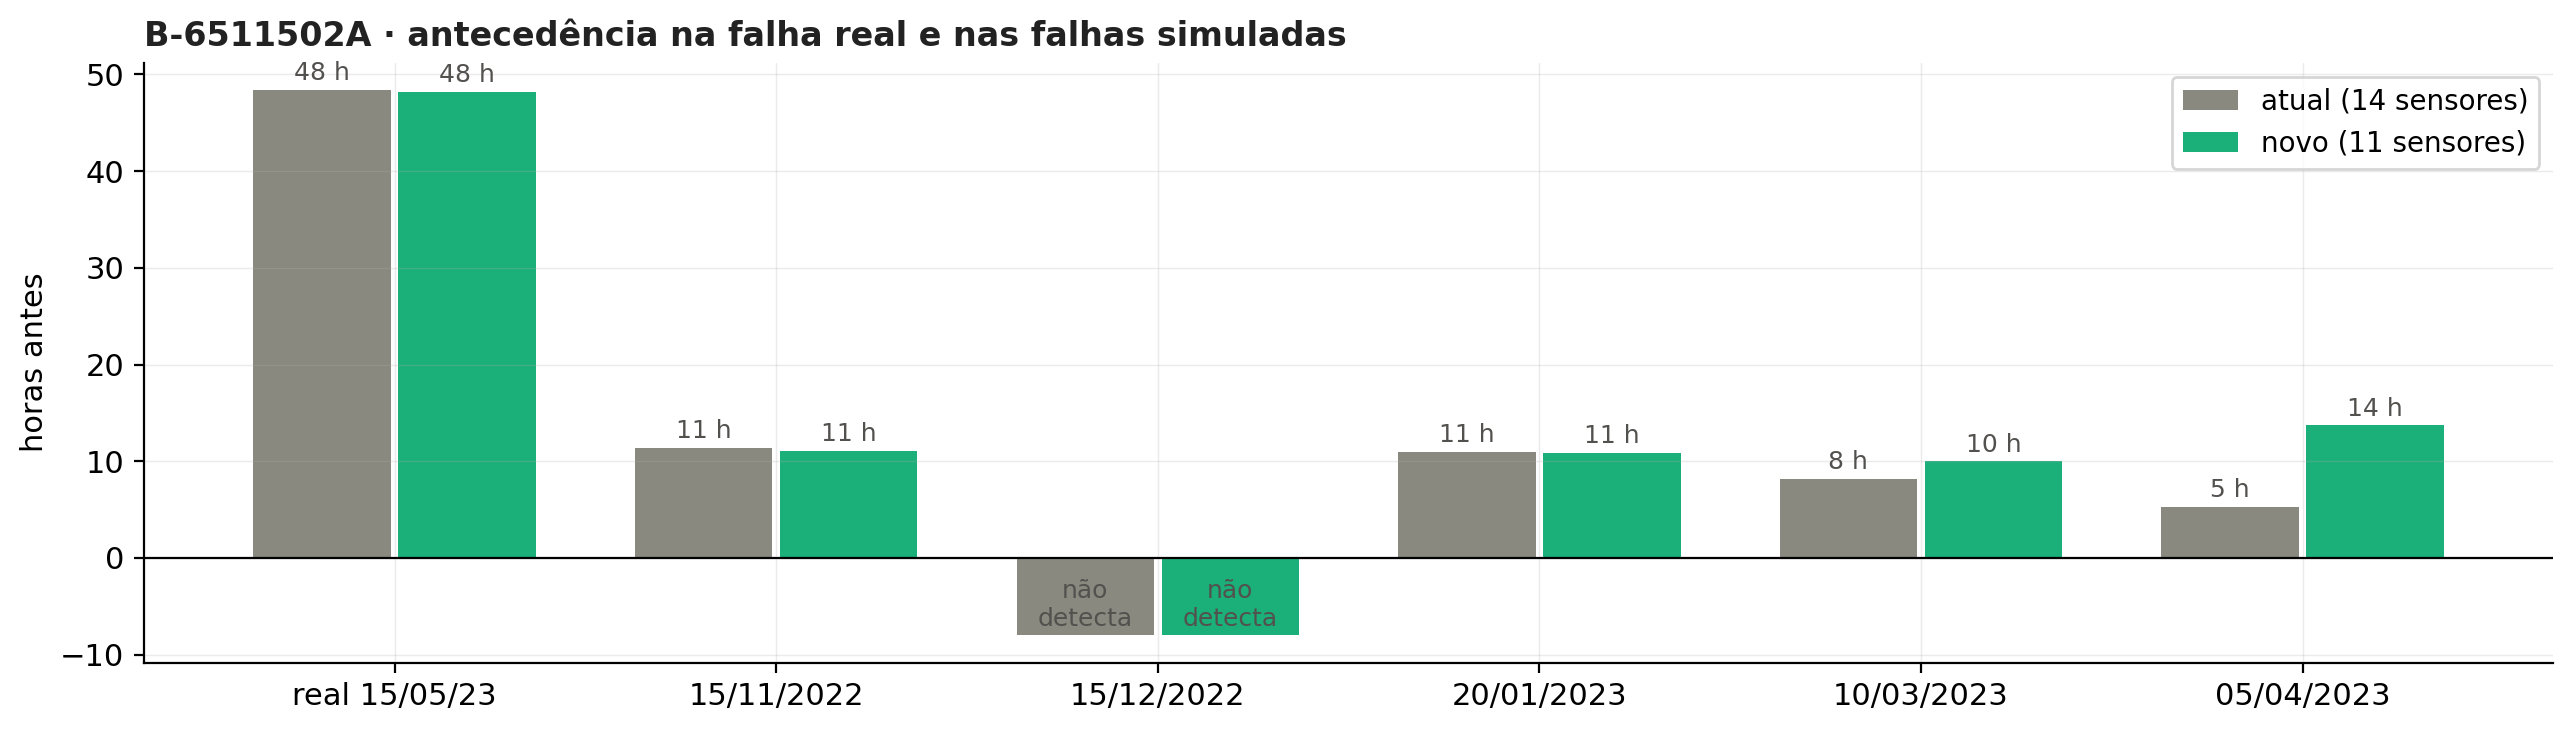

In [3]:
f = cat[cat["situação"].str.startswith("falha")].copy()
f["data"] = f["situação"].str.replace("falha simulada em ", "").str.replace("falha real de 15/05/2023", "real 15/05/23")
datas = list(dict.fromkeys(f["data"]))
fig, ax = plt.subplots(figsize=(13, 3.8))
for j, m in enumerate(MODELOS):
    d = f[f["modelo"] == m].set_index("data").reindex(datas)
    y = d["antecedência (h)"].fillna(-8)
    ax.bar(np.arange(len(datas)) + (j - 0.5) * 0.38, y, width=0.36, color=MODELOS[m][1], label=m)
    for x, v in zip(np.arange(len(datas)) + (j - 0.5) * 0.38, d["antecedência (h)"]):
        ax.text(x, (v if pd.notna(v) else -8) + 1, f"{v:.0f} h" if pd.notna(v) else "não\ndetecta", ha="center", fontsize=9, color=TEXTO)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(datas)), datas); ax.set_ylabel("horas antes"); ax.legend(fontsize=10)
estilo(ax, "B-6511502A · antecedência na falha real e nas falhas simuladas")
fig.tight_layout()
f[["modelo", "data", "antecedência (h)", "bomba_operando_%"]].pivot(index="data", columns="modelo", values="antecedência (h)").reindex(datas)

## 3. Algumas situações na série

Vibração VE-50B (o sensor da falha) com os alertas dos dois modelos, nas situações que mais separam os modelos.

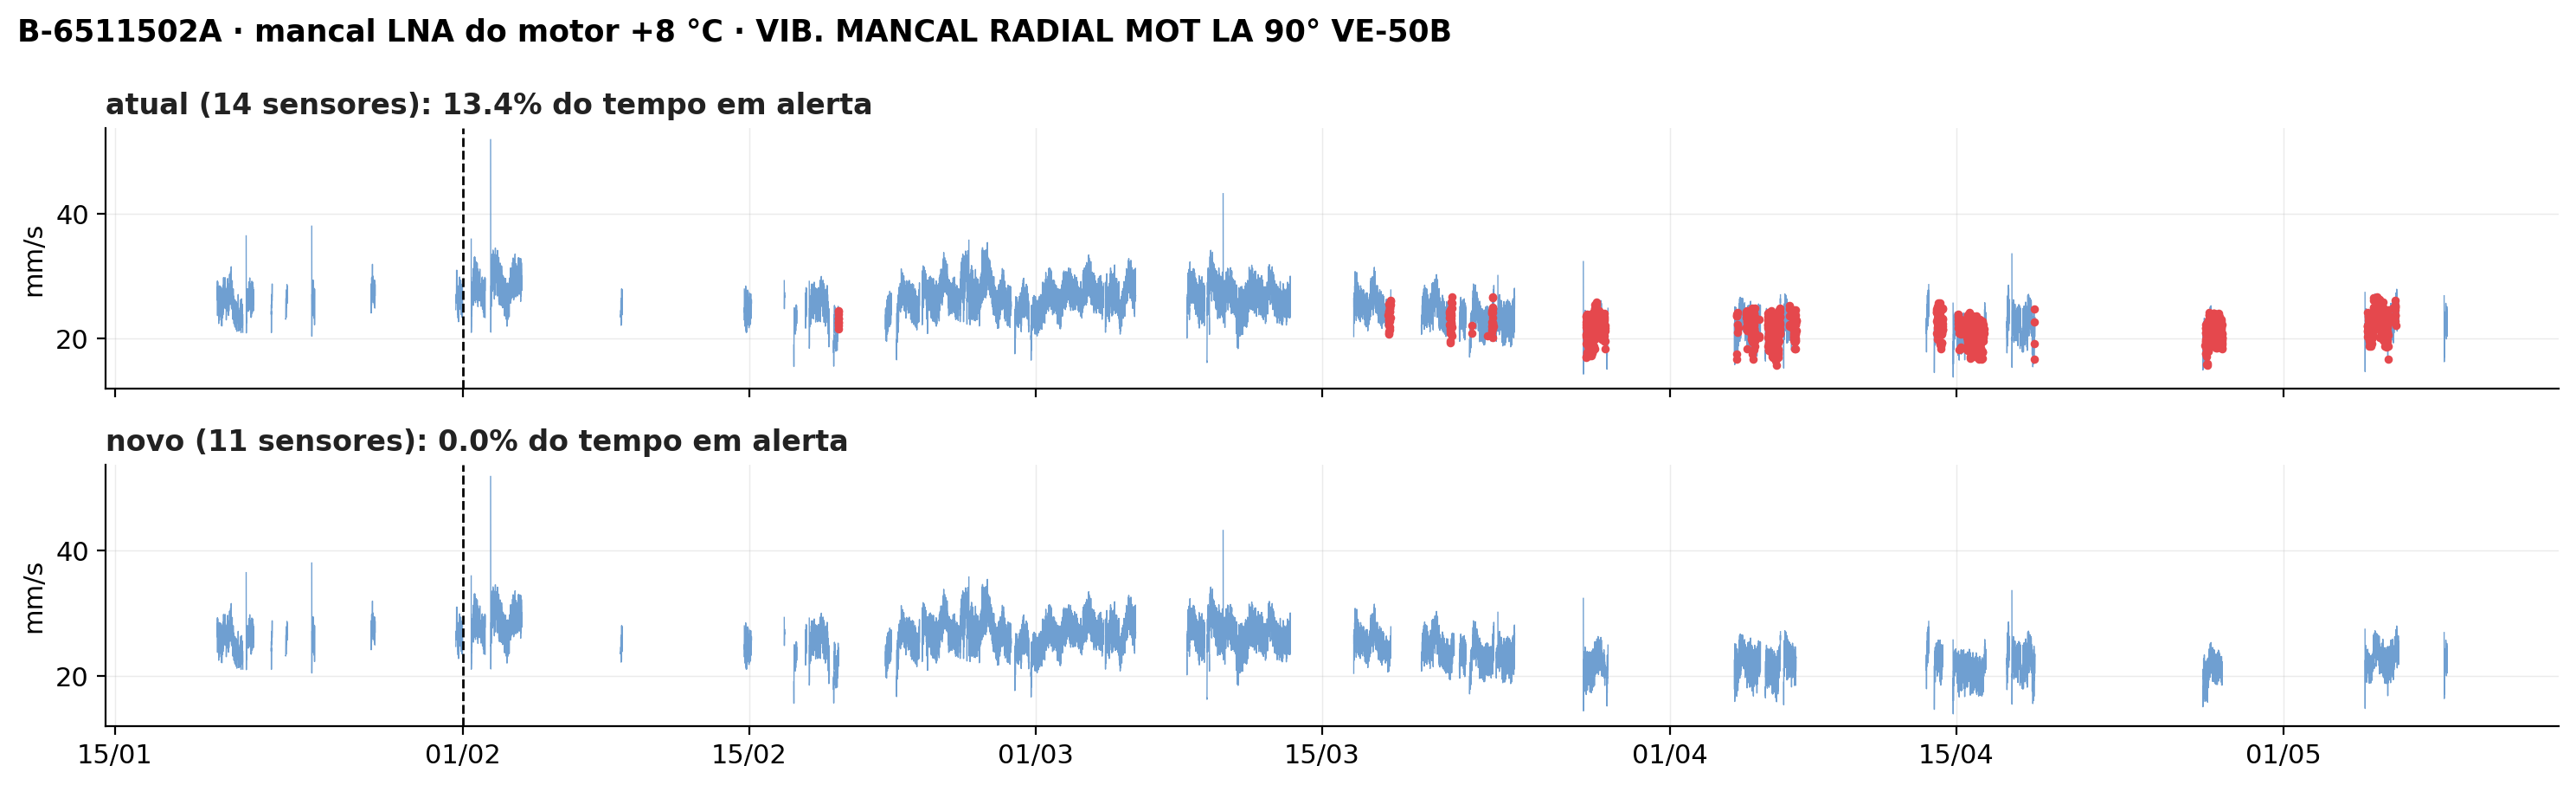

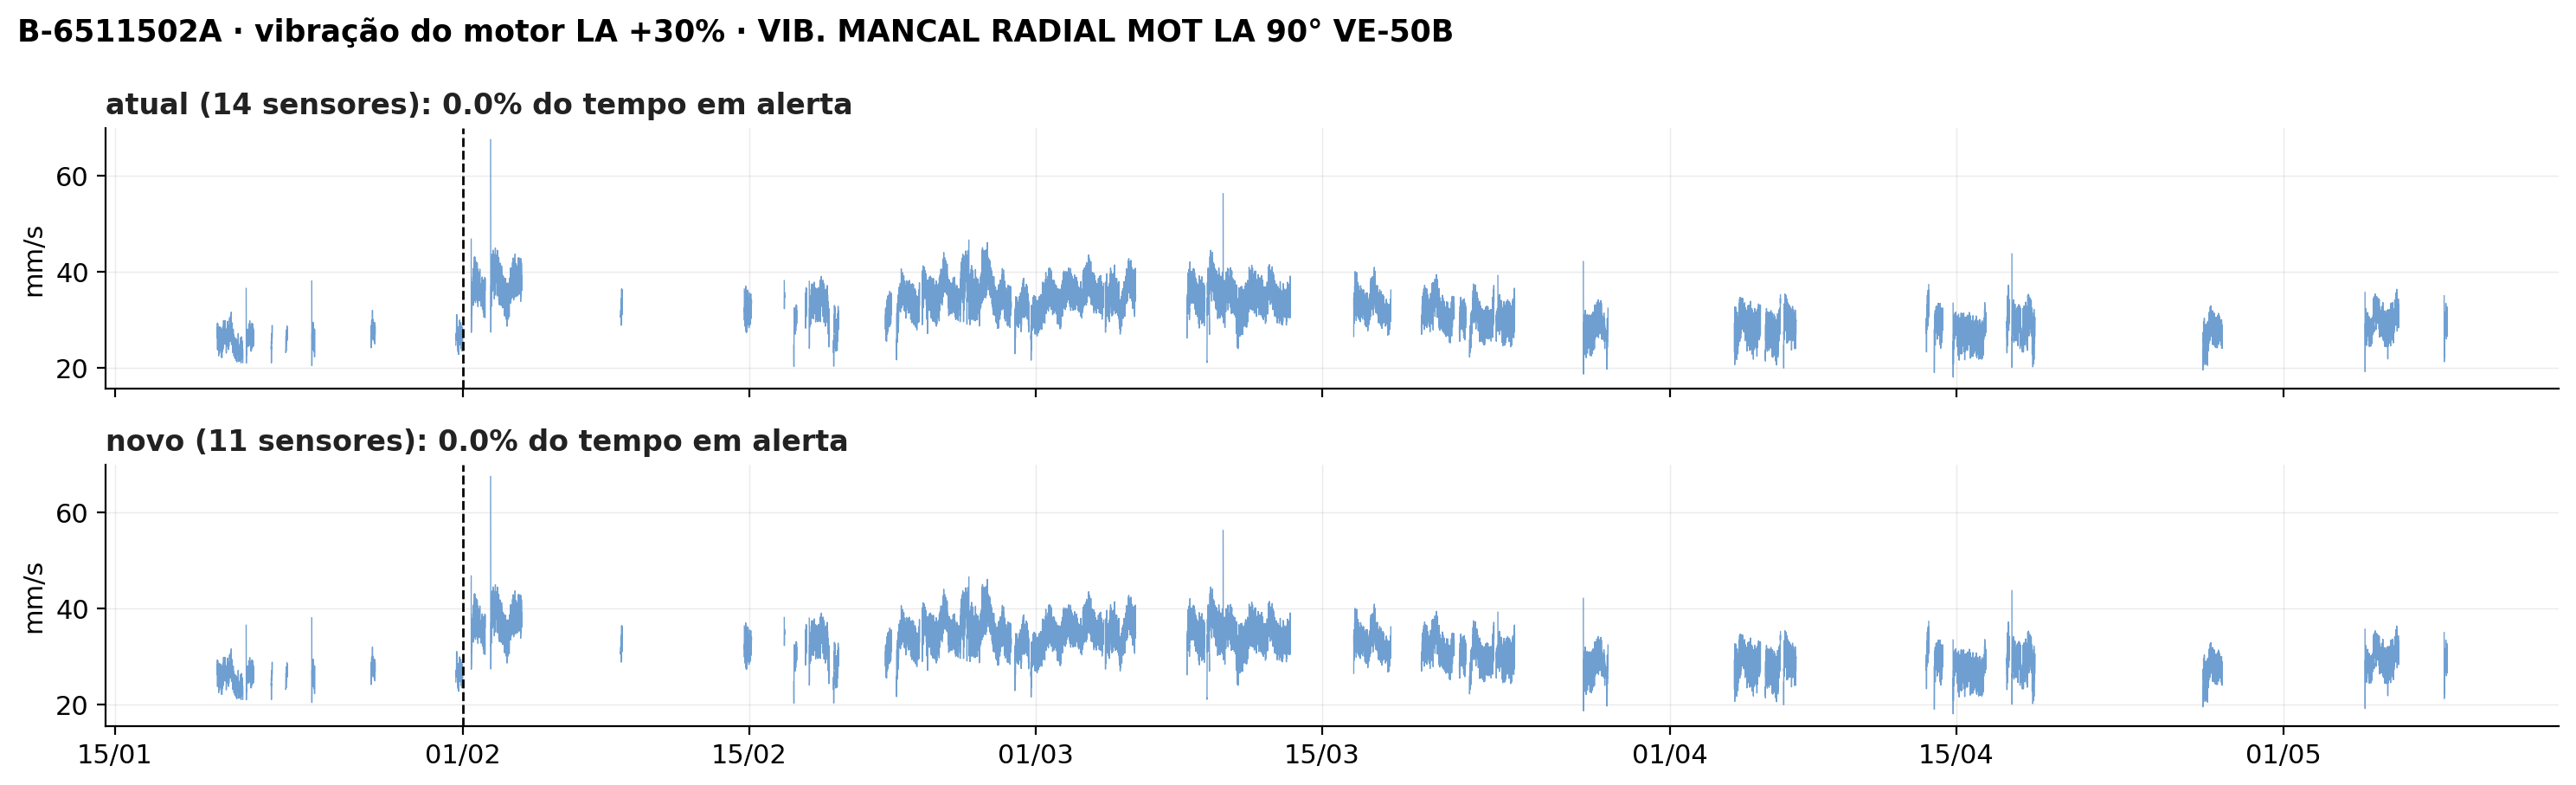

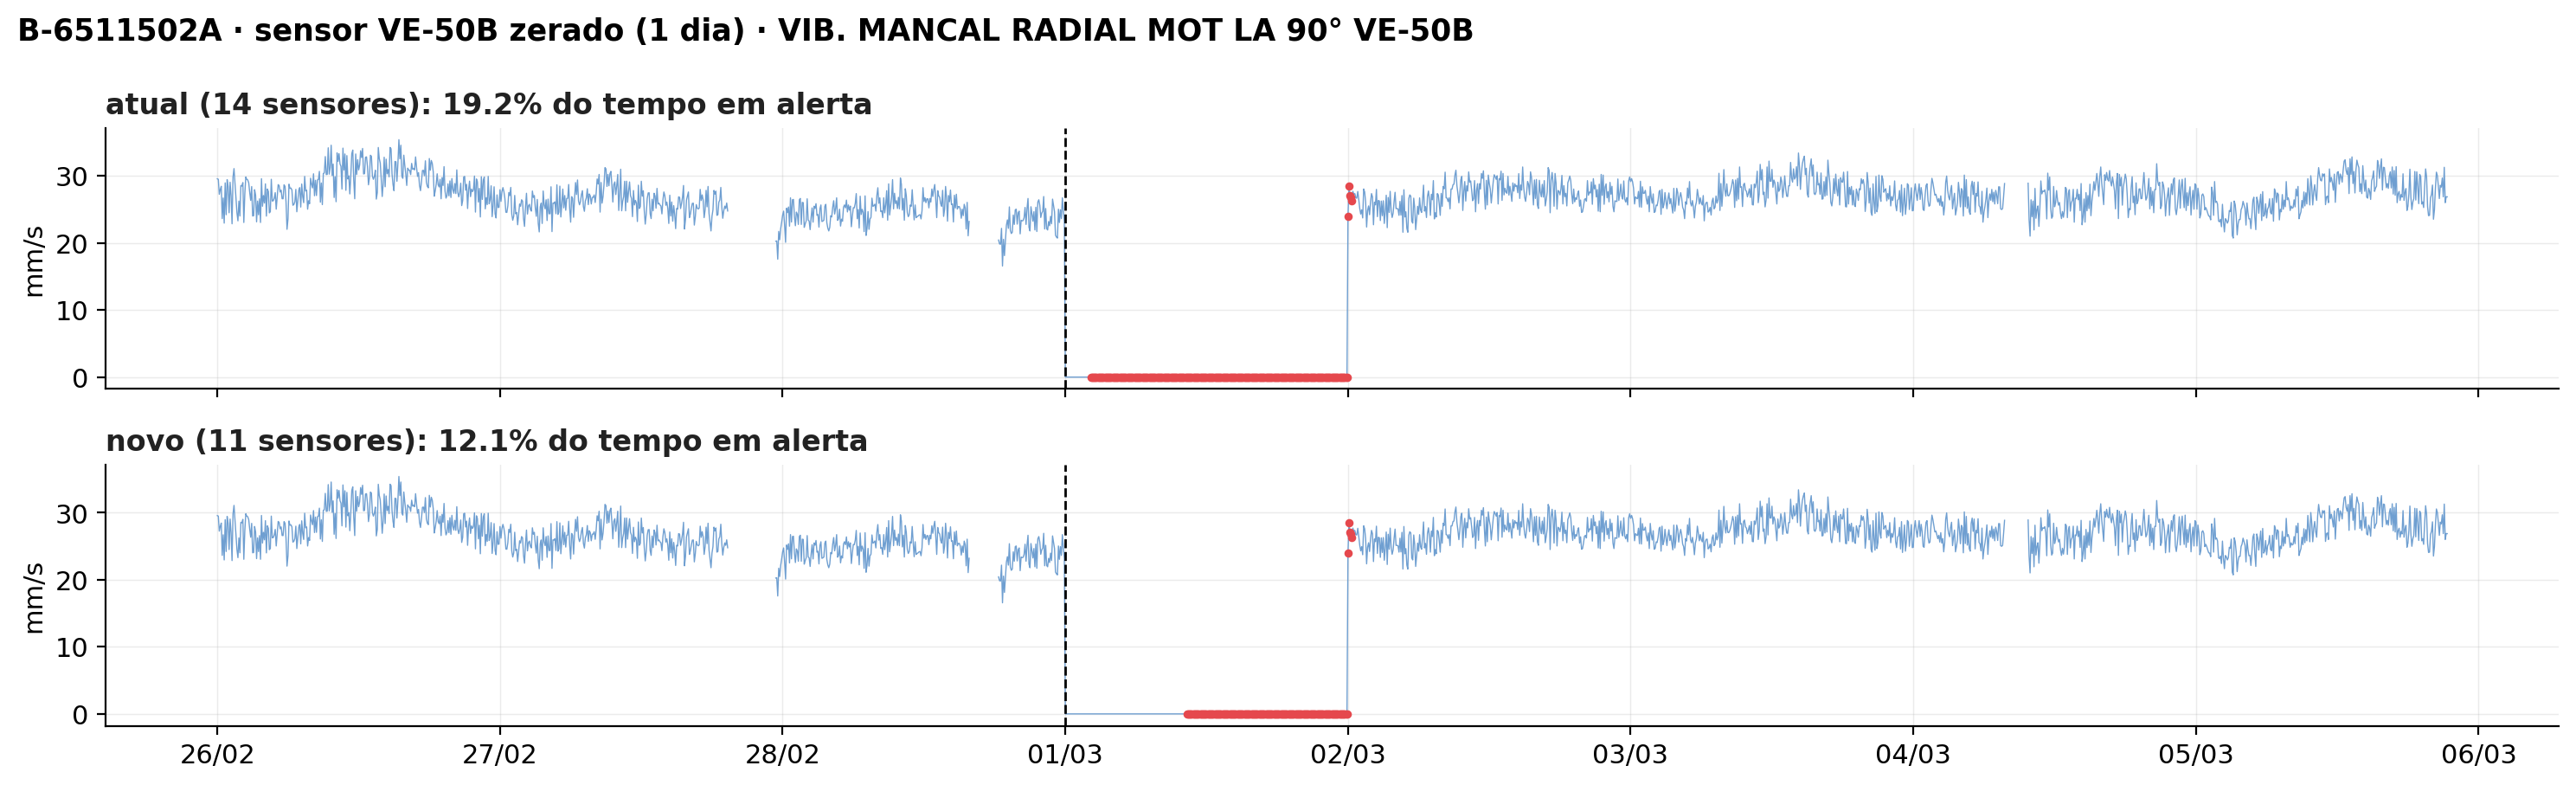

In [4]:
def painel(nome, ini, fim, sensor, un):
    mud, a0, a1, _, _ = v2.CATALOGO[nome]
    rr = v2.mudar(raw, a0, a1, mud)
    fig, axes = plt.subplots(len(MODELOS), 1, figsize=(15, 4.6), sharex=True)
    s = rr[sensor].where(rr[ds.CORR] > 60).loc[ini:fim]
    for ax, (m, (b, cor)) in zip(axes, MODELOS.items()):
        al = ds.alerta(b, rr).loc[ini:fim]
        ax.plot(s.index, s.values, color=SERIE, lw=0.5)
        p = s.reindex(al.index)[al]; ax.scatter(p.index, p.values, color=VERMELHO, s=6, zorder=3)
        ax.axvline(a0, color="black", ls="--", lw=1)
        estilo(ax, f"{m}: {100 * al.loc[a0:].mean():.1f}% do tempo em alerta"); ax.set_ylabel(un)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    fig.suptitle(f"B-6511502A · {nome} · {sensor}", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
    fig.tight_layout(); plt.show()

painel("mancal LNA do motor +8 °C", "2023-01-20", "2023-05-08", v2.VE50B, "mm/s")
painel("vibração do motor LA +30%", "2023-01-20", "2023-05-08", v2.VE50B, "mm/s")
painel("sensor VE-50B zerado (1 dia)", "2023-02-26", "2023-03-06", v2.VE50B, "mm/s")

## 4. Os 12 candidatos

O modelo escolhido é um de 12 treinos (4 configurações × 3 sementes). Cada ponto é um candidato; o escolhido está
destacado. Mostra se o resultado depende da sorte do treino.

,cand,fp_val_%,alerta_treino_%,alerta_depois_treino_%,sintetica_mediana_h,sintetica_detecta,falha_real_h
0,l128-64-32_lat16_lr0.0001_s0,0.0,0.098,0.0,8.333,4,48.1
1,l128-64-32_lat16_lr0.0001_s1,0.0,0.032,0.0,10.000,4,48.5
2,l128-64-32_lat16_lr0.0001_s2,0.0,0.029,0.0,10.917,4,48.2
3,l128-64-32_lat16_lr0.001_s0,0.0,0.000,0.0,10.000,4,48.8
4,l128-64-32_lat16_lr0.001_s1,0.0,0.000,0.0,8.333,4,48.8
5,l128-64-32_lat16_lr0.001_s2,0.0,0.144,0.0,8.250,4,48.2
6,l64-32-16_lat16_lr0.001_s0,0.0,0.000,0.0,6.750,4,47.8
7,l64-32-16_lat16_lr0.001_s1,0.0,0.078,0.0,8.750,4,48.1
8,l64-32-16_lat16_lr0.001_s2,0.0,0.000,0.0,10.833,4,48.2
9,l256-128-64_lat16_lr0.001_s0,0.0,0.929,0.0,-99.000,0,47.2


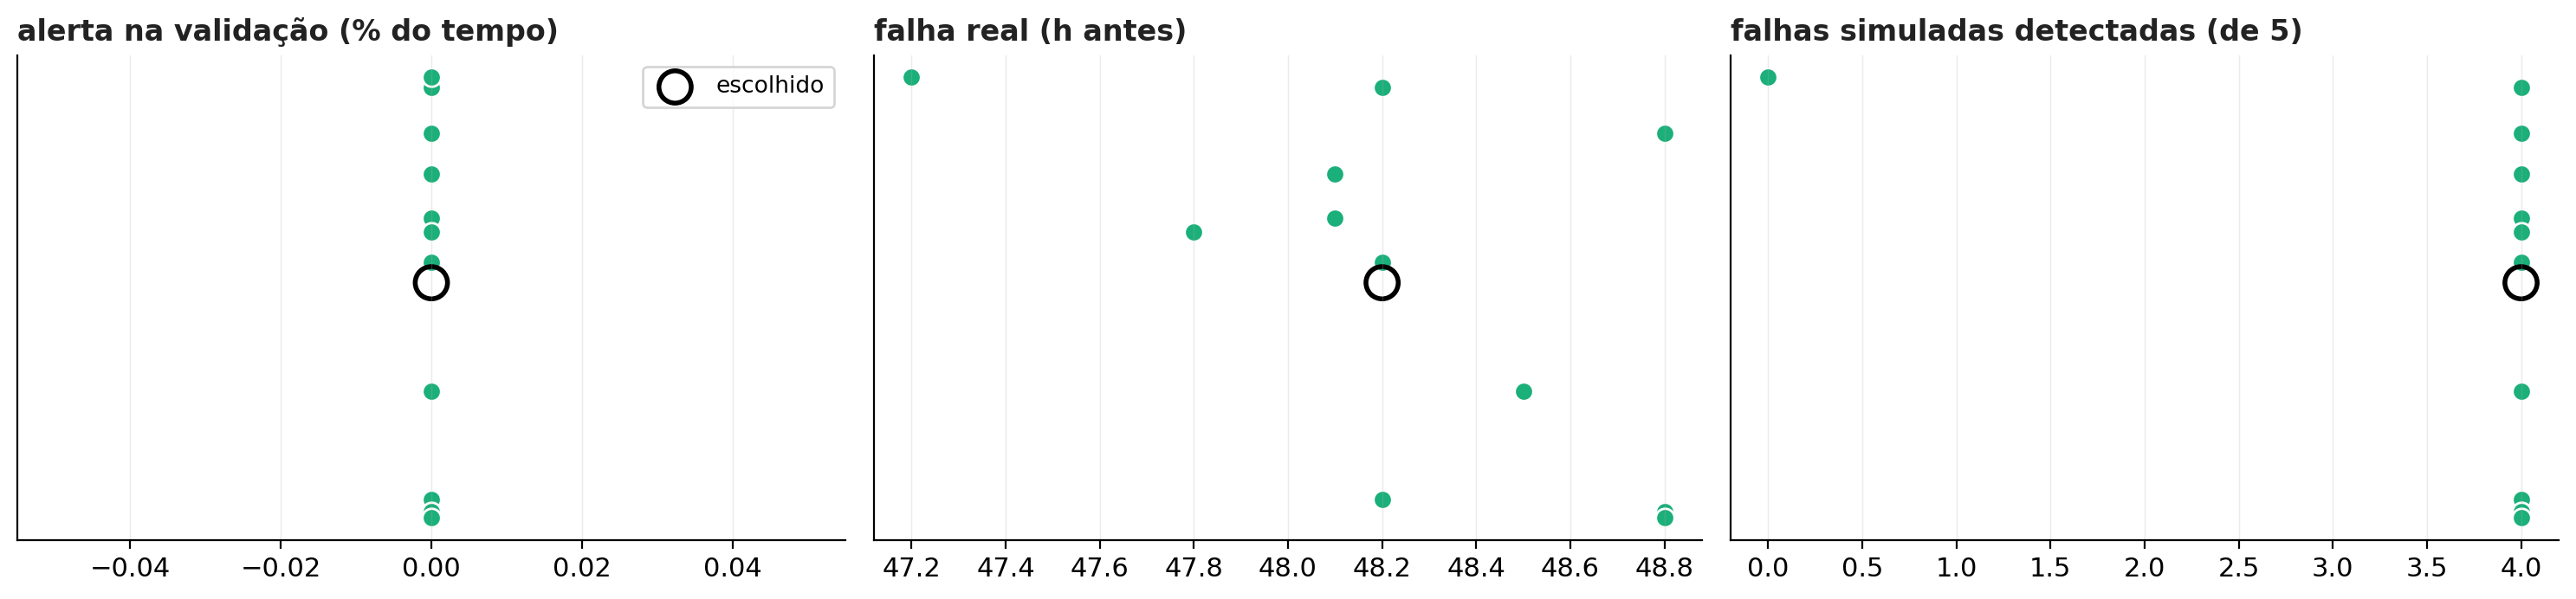

In [5]:
esc = json.loads((NOVO / "alarm.json").read_text())["threshold_calibration"]["candidate"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, tit) in zip(axes, [("fp_val_%", "alerta na validação (% do tempo)"), ("falha_real_h", "falha real (h antes)"),
                                ("sintetica_detecta", "falhas simuladas detectadas (de 5)")]):
    x = cands[col].fillna(-1)
    ax.scatter(x, np.random.default_rng(0).uniform(-0.2, 0.2, len(x)), color="#1baf7a", s=60, edgecolor="white")
    e = cands[cands["cand"] == esc][col].fillna(-1)
    ax.scatter(e, [0], s=180, facecolor="none", edgecolor="black", lw=2, label="escolhido")
    ax.set_yticks([]); estilo(ax, tit)
axes[0].legend(fontsize=9.5)
fig.tight_layout()
cands.round(3)

## 5. Conclusões

**O modelo novo faz o que o atual faz, sem o defeito da temperatura:**
- **Falha real de 15/05/2023:** alerta 48 h antes, igual ao atual (o máximo que o dado permite).
- **Falhas simuladas** (4 datas válidas; em 15/12/2022 a bomba estava parada): detecta todas, 10 a 14 h antes do fim da
  rampa de 24 h — igual ou melhor que o atual (5 a 11 h).
- **Mancal 8 ou 15 °C mais quente:** o novo não alerta; o atual fica 13% do tempo em alerta. Era o motivo da troca.
- **Período normal:** 0% de alerta nos dois.
- **Todas as vibrações 30% maiores:** os dois alertam em ~13 h. Vibração alta é o que antecede a falha aqui.
- **Sensor de vibração zerado:** os dois alertam (o novo em 10 h, o atual em 2 h) — é falha de instrumento, e o alerta
  vem com o sensor apontado pelo erro de reconstrução.
- **Robustez:** 11 dos 12 candidatos detectam todas as falhas simuladas e os 12 detectam a falha real; o escolhido não
  depende de sorte do treino.

**Limites, para a operação saber o que o modelo NÃO vê:**
- **Subida moderada só na vibração do mancal LA do motor** (+10% a +30%, permanente): nenhum dos dois modelos alerta;
  com +50% o novo só alerta semanas depois. O modelo reage a saltos grandes (a falha de 2023 foi ~+8 desvios) ou a várias
  vibrações subindo juntas, não a um mancal subindo devagar. Para isso: uma regra simples de limite por sensor de vibração.
- **Sensor travado:** nenhum alerta (o valor parece normal) — fica com o monitor de dado congelado (M7).
- **Deslocamento axial e temperatura:** fora do modelo — ficam com regra de limite (axial) e monitor M8 (temperatura).
- **Mudança de regime de operação** (descarga −8 bar, corrente −15 A): o novo alerta 2% do tempo (o atual 1%). Se o
  regime novo for normal, é caso de retreino.

**Recomendação:** usar o modelo novo no deploy do B-6511502A, junto com três vigias simples fora do modelo: limite por
sensor de vibração, limite do deslocamento axial e o monitor de temperatura/dado congelado.

**Um alerta a mais no histórico, que parece útil:** no ano inteiro de 2022–23 o modelo novo alerta em dois momentos —
a falha (12/05/2023) e **22/07/2022 18h**, que o atual não pega. Nesse dia, a partir das 16h, a pressão de sucção caiu
de ~10 para ~1 bar, a descarga e todas as vibrações despencaram (−6 desvios) e a corrente foi caindo com o motor ainda
ligado: a bomba perdendo a sucção. É um evento de processo, não da máquina — vale confirmar com a operação o que houve.
